# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name: Arnoud van Niekerk**  
**Title of the experiment: Bepaling van de constante van Boltzmann**  
**Starting date: 11-11-2026**  
**Expected enddate: 23-11-2026**  
**Partner: Feltse Hoekstra**  
**Goal of the experiment: Het bepalen van de constante van Boltzmann**  
**Research question: Kan je met behulp van een spanningsdeler en een diode, de constante van Boltzmann bepalen met behulp van een verband tussen de spanning en stroomsterkte over de diode.**  
**Expectations or Hypothesis: We verwachten als we de spanning en stroomsterkte over de diode meten en deze plotten met een log schaal op de stroomsterkte as, dat er vanaf $U_D$ = 0.1 V een lineair verband zichtbaar is.**  
**Desired accuracy: -**  




In [1]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from scipy.constants import k

# Preparation
 


**Assignments:-**  

**Method:-**  
**Theory:-**  
**Independent variable: $q$, $I_0$, $n$, $k_b$, $T$**  
**Dependent variable: $I_D$**  
**Controlled variablen: $U_D$**  
**Measurement instruments \& Settings: 3.5 digit DMM en 5.5 digit DMM**  
**Procedure:-**  
**Setup(drawing or picture):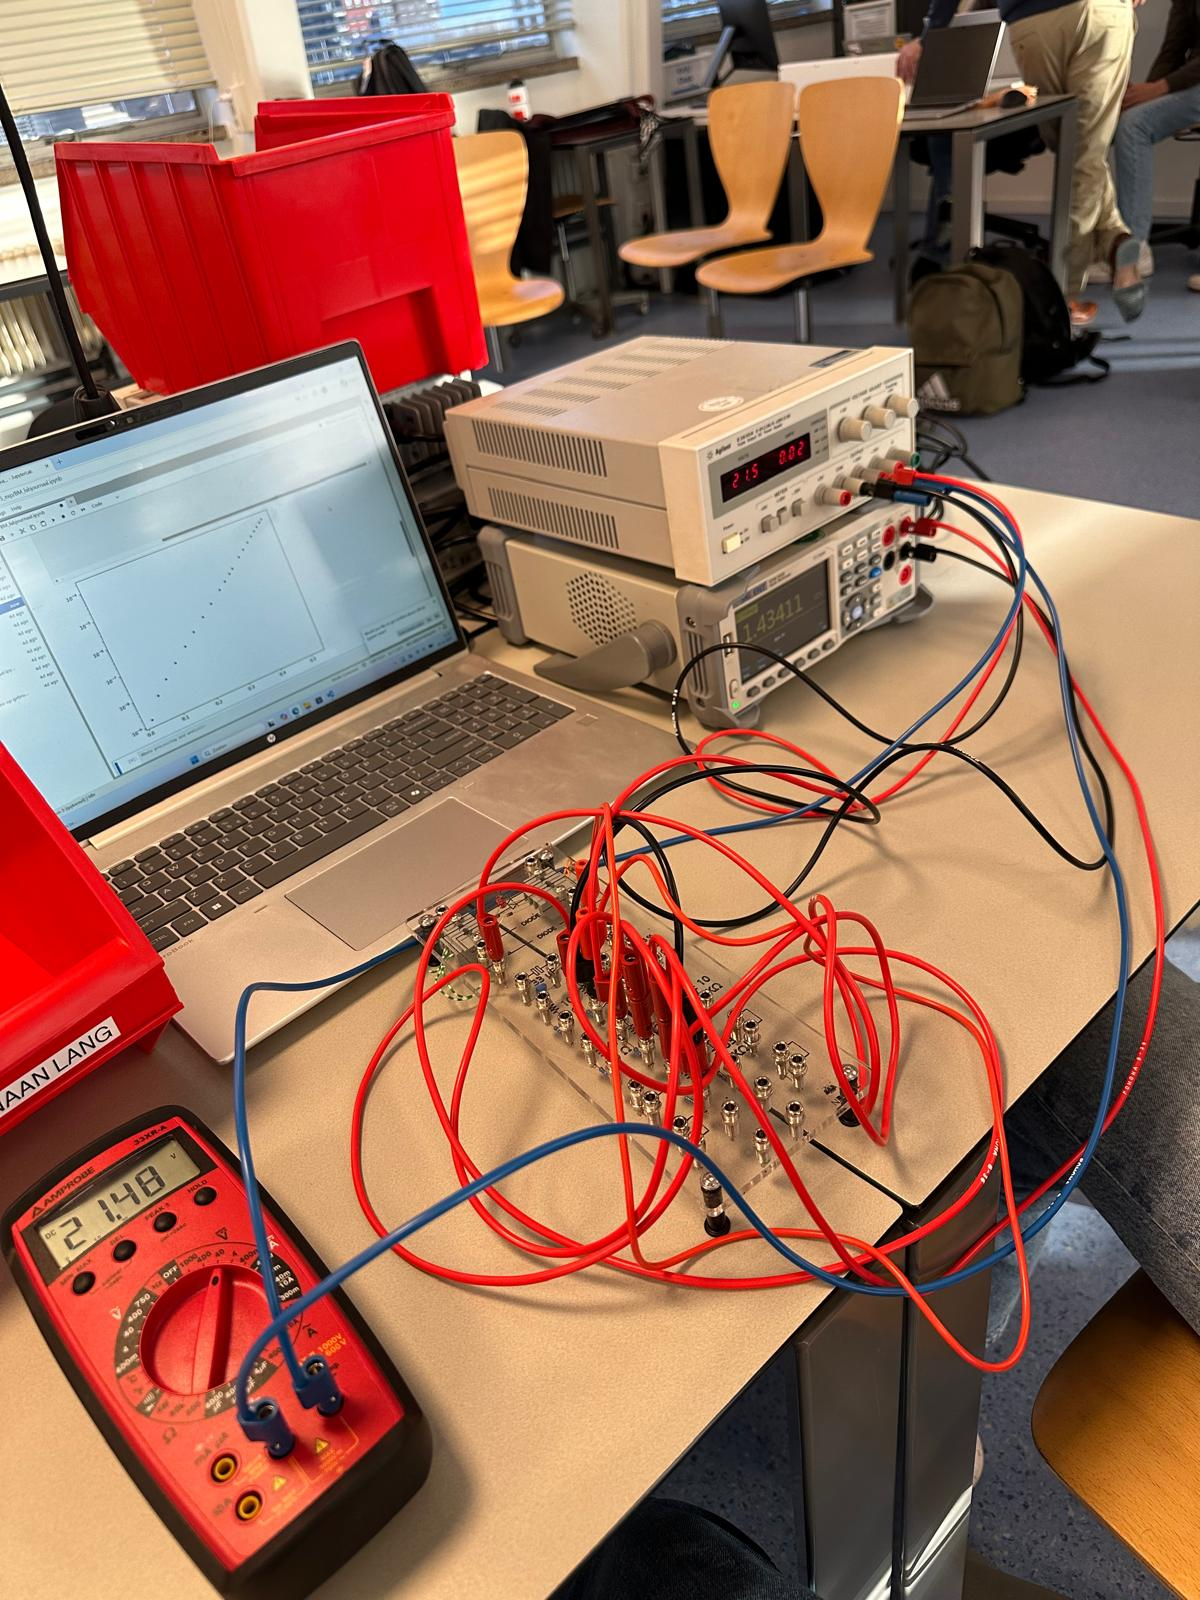**  
**Notes:-**  
**About accuracy:-**  


# Execution

In [10]:
# Measurements: Explain the names of variables provide only raw data in np.arrays!

Resistance_arr = np.array([10, 100, 330, 330, 470, 1e3, 4.7e3, 1.0e4, 1.0e4, 3.3e4]) #Ω
Resistances_3_5 = np.array([10.2, 100.4, 328.0, 324.5, 0.47e3, 0.99e3, 4.67e3, 9.99e3, 9.94e3, 32.90e3]) #Ω
Resistances_5_5 = np.array([10.009, 100.122, 0.32804e3, 0.32452e3, 0.46914e3, 0.99577e3, 4.6683e3, 9.9861e3, 9.9358e3, 32.894e3]) #Ω

#Strijdigheidsanalyse laagtste Ohmse weerstand

a = Resistances_3_5[0]
b = Resistances_5_5[0]
a_unc = 0.007*a + 0.01
b_unc = 0.00020*b + 0.00003*2.0e3
if a-b > 2*np.sqrt(a_unc**2+b_unc**2):
    print('De weerstanden zijn strijdig met elkaar.')
else:
    print('De weerstanden zijn niet strijdig met elkaar.')

R_dubbel = np.array([10.113, 99.357, 0.32991e3, 0.32596e3, 0.46756e3, 0.99471e3, 4.6923e3, 9.9988e3, 9.9735e3, 33.115e3]) #Ω

R_1 = np.array([15.0178]) #Ω
R_2 = np.array([4.9810]) #Ω
R_Bron = np.array([20.0004]) #Ω
R_1_2 = np.array([20.0009]) #Ω

#Analyse gemeten waarden R_1_2

I_Bron = np.array([15.1e-3]) #A
I = R_1/Resistances_5_5[5] #A

I_1 = 1.50e-3 #A
I_2 = 1.407e-3 #A
#De stroomsterkte is nauwkeuriger gemeten bij 4mA

De weerstanden zijn niet strijdig met elkaar


**Observations:-**  
**Notes:-**  

## Processing
**Description of processing of raw data into scientific evidence:**


k_B =  1.4104783324735348e-23  +/-  1.3442374745013188e-25


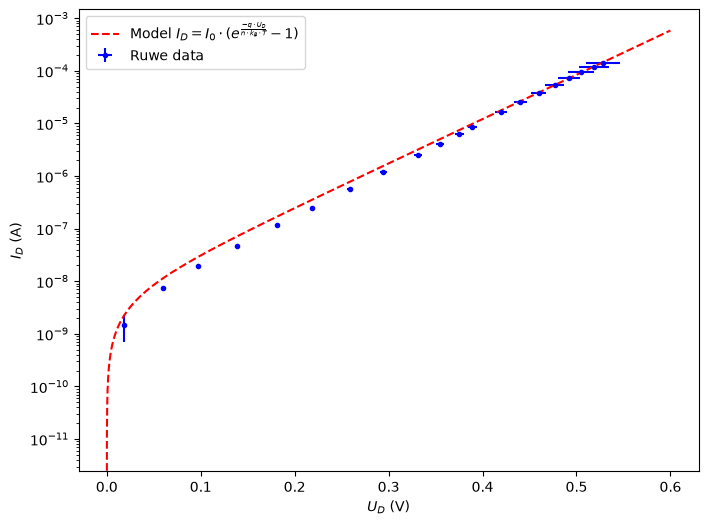

In [3]:
#Data processing and analysis:
#Beginwaarden

R_1 = Resistances_5_5[7]
R_2 = Resistances_5_5[5]
R_3 = Resistances_5_5[1]
n = 2.0 #De idealiteitsfactor van silicium. 
unc_n = 0.1 #De onzekerheid in de idealiteitsfactor van silicium. 
T = 293 #Kamertemperatuur in Kelvin. 
q = -1.602176634e-19 #Lading van een elektron. 

#Gemeten waarden van de bronspanning en de spanning over de weerstand R1. 
U_B = np.array([0.20, 0.66, 1.07, 1.52, 2.00, 2.42, 2.89, 3.35, 3.90, 4.33, 4.79, 5.19, 6.40, 7.57, 9.22, 11.18, 13.38, 15.88, 18.86, 21.48]) 
U_1 = np.array([0.015e-3, 0.074e-3, 0.193e-3, 0.474e-3, 1.166e-3, 2.514e-3, 5.633e-3, 11.741e-3, 25.188e-3, 41.083e-3, 62.341e-3, 85.067e-3, 164.970e-3, 0.25170, 0.38267, 0.54477, 0.73033, 0.94583, 1.20450, 1.43428])

#Berekende waarden van de spanning over de diode en de stroomsterkte door de diode. 
U_D = R_3*U_B/(R_3+R_2)-U_1
I_D = U_1/R_1

u_U_1_begin = 0.00015*U_1[0:12] + 0.00004*0.200
u_U_1_eind = 0.00015*U_1[12:] + 0.00003*2.0
u_U_1 = np.concatenate((u_U_1_begin, u_U_1_eind))

u_R_1 = 0.00020*R_1 + 0.00003*2.0e3
u_R_2 = 0.00020*R_2 + 0.00003*2.0e3
u_R_3 = 0.00020*R_3 + 0.00003*2.0e4

u_U_B = 0.007*U_B + 0.01

u_U_D = np.sqrt((U_B*R_2/(R_3+R_2)**2*u_R_3)**2 + (R_3/(R_3+R_2)*u_U_B)**2 + (U_B*R_3/(R_3+R_2)**2*u_R_2)**2 + u_U_1**2)
u_I_D = np.sqrt((u_U_1/U_1)**2 + (u_R_1/R_1)**2)*I_D

def f_Boltzmann(U_Diode, I_0, k_B): #Het model dat de data beschrijft. 
    return I_0*(np.exp(-q*U_Diode/(n*k_B*T))-1)

val, cov = curve_fit(f_Boltzmann, U_D, I_D, p0=[1.0e-9, 1.38e-23]) #De gefitte functie. 
print("k_B = ", val[1], " +/- ", np.sqrt(cov[1, 1]))
x_test = np.linspace(0, 0.6, 10000)
y_fit = f_Boltzmann(x_test,*val)

plt.figure(figsize=(8, 6))
plt.errorbar(U_D, I_D, xerr=u_U_D, yerr=u_I_D, fmt="b.", label="Ruwe data")
plt.plot(x_test, y_fit, "r--", label=r"Model $I_{D} = I_{0}\cdot (e^{\frac {-q\cdot U_{D}} {n\cdot k_{B}\cdot T}} - 1)$")
plt.xlabel("$U_D$ (V)")
plt.ylabel("$I_D$ (A)")
plt.yscale("log")
plt.legend()
plt.savefig("Grafiek_data.png")
plt.show()

In [4]:
#Data processing and analysis:
#Strijdigheidsanalyse constante van Boltzmann
if (np.abs(k - val[1]) <= 2*np.sqrt(cov[1, 1])): 
    print("De waarden zijn niet strijdig")
else:
    print("De waarden zijn strijdig")

De waarden zijn strijdig


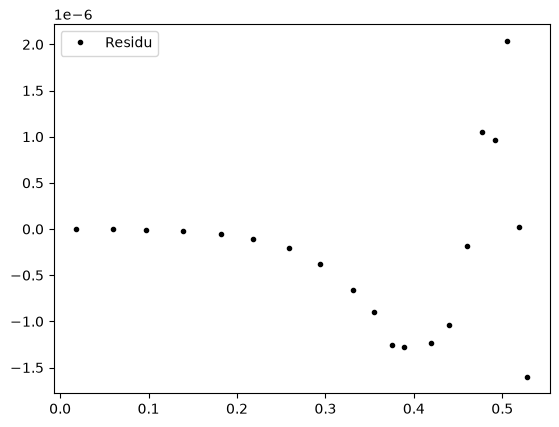

In [5]:
#Data processing and analysis:
y_res = I_D - f_Boltzmann(U_D,*val)
plt.figure()
plt.plot(U_D,y_res,'k.',label = 'Residu')
plt.legend(loc='upper left')
plt.show()

**Describing the pattern in the processed data:**  


In [6]:
#Calculations of e.a. measurement uncertainties, and providing final answers.


**Notes:**  

# Discussion



# Conclusion

# Additional notes, remarks, explanations, thoughts etc